# Goal

This notebook investigates a narrower question than pipeline QA:

**Are the removed features actually justified?**

It does not verify whether the preprocessing pipeline executed correctly. That was covered separately in the post-run audit.

Instead, this notebook asks whether the *feature-removal policy* is scientifically and statistically reasonable.

Each section follows the same pattern:

Question -> Analysis -> Visualization -> Interpretation -> Conclusion

Where evidence is unavailable in this repository, the notebook says so explicitly.

# Load Data

Load the original processed dataset and the exported removal metadata.

At this stage we only establish what data we have; we do not draw conclusions yet.

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import Markdown, display

pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 160)

NOTEBOOK_DIR = Path.cwd()
PIPELINE_ROOT = NOTEBOOK_DIR.parents[1]
PROJECT_ROOT = PIPELINE_ROOT.parent

config_path = PIPELINE_ROOT / 'config.yaml'
with config_path.open('r', encoding='utf-8') as handle:
    config = yaml.safe_load(handle)

input_csv = (PIPELINE_ROOT / config['paths']['input_csv']).resolve()
raw_df = pd.read_csv(input_csv)
df = raw_df.drop_duplicates().reset_index(drop=True)

removed_df = pd.read_csv(NOTEBOOK_DIR / 'removed_features.csv')
retained_df = pd.read_csv(NOTEBOOK_DIR / 'retained_features.csv')

subject_id_column = config['dataset']['subject_id_column']
removed_features = removed_df['feature'].tolist() 
retained_features = retained_df['feature'].tolist()

In [2]:
pd.DataFrame(
    {
        'item': ['raw dataset shape', 'deduplicated dataset shape', 'removed feature count', 'retained feature count'],
        'value': [str(raw_df.shape), str(df.shape), len(removed_features), len(retained_features)],
    }
)

,item,value
0,raw dataset shape,"(407504, 160)"
1,deduplicated dataset shape,"(407446, 160)"
2,removed feature count,64
3,retained feature count,95


# Removed Feature Categories

Question: what kinds of features were removed?

Rather than reading the answer from `config.yaml`, we first group the removed features based on their names.

In [3]:
def categorize_removed_feature(feature: str) -> str:
    if feature.endswith('_count'):
        return 'Count Features'
    if feature.startswith('ST_Elev_') and feature.endswith('_iqr'):
        return 'ST Elevation IQR'
    return 'Others'

removed_category_df = pd.DataFrame({'feature': removed_features})
removed_category_df['category'] = removed_category_df['feature'].map(categorize_removed_feature)
removed_category_df.head()

,feature,category
0,RR_Mean_Global_count,Count Features
1,S_Amp_V1_count,Count Features
2,S_Amp_V2_count,Count Features
3,S_Amp_V3_count,Count Features
4,Q_Amp_I_count,Count Features


In [4]:
removed_category_summary = (
    removed_category_df.groupby('category')
    .agg(feature_count=('feature', 'size'))
    .reset_index()
    .sort_values('feature_count', ascending=False)
)
removed_category_summary

,category,feature_count
0,Count Features,52
1,ST Elevation IQR,12


In [5]:
removed_category_df.groupby('category')['feature'].apply(list)

category
Count Features      [RR_Mean_Global_count, S_Amp_V1_count, S_Amp_V...
ST Elevation IQR    [ST_Elev_I_iqr, ST_Elev_II_iqr, ST_Elev_III_iq...
Name: feature, dtype: object

# Investigation of Count Features

Question: **Are the `*_count` features redundant?**

This section looks for direct evidence of redundancy inside the current dataset.

Analyses below:
- row-wise unique value counts across the count-feature block
- pairwise correlations
- exact-match percentages to the retained representative count feature
- distribution of differences relative to the retained representative
- a small count-feature heatmap

In [6]:
count_cols = [col for col in df.columns if col.endswith('_count')]
removed_count_cols = [col for col in removed_features if col.endswith('_count')]
retained_count_cols = [col for col in retained_features if col.endswith('_count')]
count_reference = retained_count_cols[0] if retained_count_cols else None

pd.DataFrame(
    {
        'item': ['all count features in deduplicated data', 'removed count features', 'retained count features', 'retained representative'],
        'value': [len(count_cols), len(removed_count_cols), len(retained_count_cols), count_reference],
    }
)

,item,value
0,all count features in deduplicated data,53
1,removed count features,52
2,retained count features,1
3,retained representative,QRS_Dur_Global_count


In [7]:
row_unique_counts = df[count_cols].nunique(axis=1)
row_unique_count_summary = (
    row_unique_counts.value_counts()
    .sort_index()
    .rename_axis('unique_values_across_count_features')
    .reset_index(name='row_count')
)
row_unique_count_summary['percentage_of_rows'] = row_unique_count_summary['row_count'] / len(df) * 100
row_unique_count_summary

,unique_values_across_count_features,row_count,percentage_of_rows
0,1,402416,98.765481
1,2,5030,1.234519


In [8]:
count_corr = df[count_cols].corr()
upper_triangle = count_corr.where(np.triu(np.ones(count_corr.shape), k=1).astype(bool))
pairwise_corr_values = upper_triangle.stack().reset_index()
pairwise_corr_values.columns = ['feature_a', 'feature_b', 'correlation']

pairwise_corr_values['abs_correlation'] = pairwise_corr_values['correlation'].abs()
pairwise_corr_values['near_perfect_abs_corr'] = pairwise_corr_values['abs_correlation'] >= 0.999

pairwise_corr_values[['correlation', 'abs_correlation']].describe()

,correlation,abs_correlation
count,1378.000000,1378.000000
mean,0.999982,0.999982
std,0.000091,0.000091
min,0.999521,0.999521
25%,1.000000,1.000000
50%,1.000000,1.000000
75%,1.000000,1.000000
max,1.000000,1.000000


In [9]:
exact_match_rows = []
difference_rows = []

for feature in removed_count_cols:
    diff = df[feature] - df[count_reference]
    exact_match_rows.append(
        {
            'feature': feature,
            'exact_match_ratio': (diff == 0).mean(),
            'mean_difference': diff.mean(),
            'min_difference': diff.min(),
            'max_difference': diff.max(),
            'unique_difference_count': diff.nunique(),
        }
    )
    difference_rows.append(
        {
            'feature': feature,
            'difference_distribution': diff.value_counts().sort_index().to_dict(),
        }
    )

count_redundancy_df = pd.DataFrame(exact_match_rows).sort_values(
    by=['exact_match_ratio', 'feature'],
    ascending=[False, True],
)
count_redundancy_df

,feature,exact_match_ratio,mean_difference,min_difference,max_difference,unique_difference_count
12,Q_Amp_III_count,0.987655,0.012345,0,1,2
8,Q_Amp_II_count,0.987655,0.012345,0,1,2
4,Q_Amp_I_count,0.987655,0.012345,0,1,2
28,Q_Amp_V1_count,0.987655,0.012345,0,1,2
32,Q_Amp_V2_count,0.987655,0.012345,0,1,2
36,Q_Amp_V3_count,0.987655,0.012345,0,1,2
40,Q_Amp_V4_count,0.987655,0.012345,0,1,2
44,Q_Amp_V5_count,0.987655,0.012345,0,1,2
48,Q_Amp_V6_count,0.987655,0.012345,0,1,2
24,Q_Amp_aVF_count,0.987655,0.012345,0,1,2


In [10]:
difference_summary_df = pd.DataFrame(difference_rows)
difference_summary_df.head(10)

,feature,difference_distribution
0,RR_Mean_Global_count,"{0: 402416, 1: 5030}"
1,S_Amp_V1_count,"{0: 402416, 1: 5030}"
2,S_Amp_V2_count,"{0: 402416, 1: 5030}"
3,S_Amp_V3_count,"{0: 402416, 1: 5030}"
4,Q_Amp_I_count,"{0: 402416, 1: 5030}"
5,R_Amp_I_count,"{0: 402416, 1: 5030}"
6,T_Amp_I_count,"{0: 402416, 1: 5030}"
7,ST_Elev_I_count,"{0: 402416, 1: 5030}"
8,Q_Amp_II_count,"{0: 402416, 1: 5030}"
9,R_Amp_II_count,"{0: 402416, 1: 5030}"


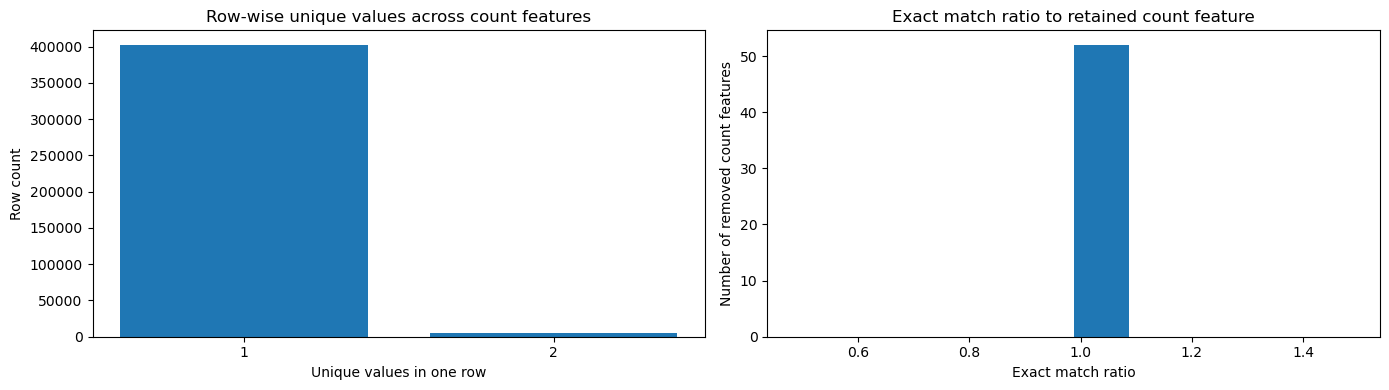

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].bar(row_unique_count_summary['unique_values_across_count_features'].astype(str), row_unique_count_summary['row_count'])
axes[0].set_title('Row-wise unique values across count features')
axes[0].set_xlabel('Unique values in one row')
axes[0].set_ylabel('Row count')

axes[1].hist(count_redundancy_df['exact_match_ratio'], bins=10)
axes[1].set_title('Exact match ratio to retained count feature')
axes[1].set_xlabel('Exact match ratio')
axes[1].set_ylabel('Number of removed count features')

plt.tight_layout()

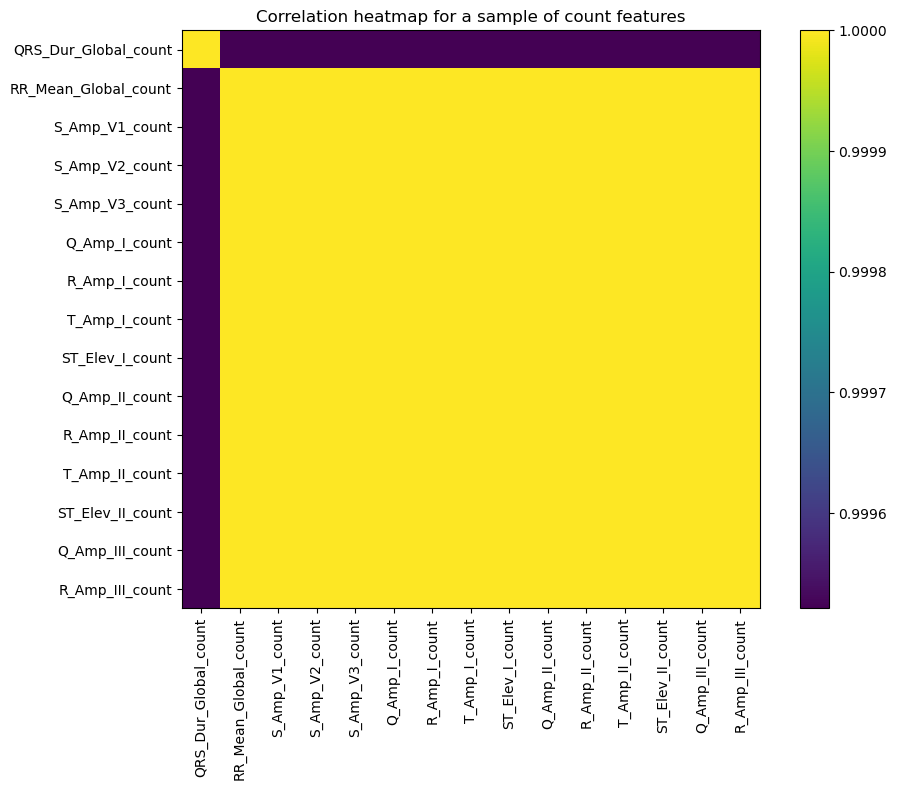

In [12]:
sample_count_features = count_cols[:15]
sample_corr = df[sample_count_features].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(sample_corr, cmap='viridis', vmin=sample_corr.values.min(), vmax=1.0)
ax.set_xticks(range(len(sample_count_features)))
ax.set_yticks(range(len(sample_count_features)))
ax.set_xticklabels(sample_count_features, rotation=90)
ax.set_yticklabels(sample_count_features)
ax.set_title('Correlation heatmap for a sample of count features')
fig.colorbar(im, ax=ax)
plt.tight_layout()

In [13]:
rows_with_nonzero_difference = []
for feature in removed_count_cols[:8]:
    diff = df[feature] - df[count_reference]
    nonzero = diff[diff != 0]
    rows_with_nonzero_difference.append(
        {
            'feature': feature,
            'nonzero_difference_rows': int((diff != 0).sum()),
            'difference_values_seen': sorted(nonzero.unique().tolist())[:10],
        }
    )
pd.DataFrame(rows_with_nonzero_difference)

,feature,nonzero_difference_rows,difference_values_seen
0,RR_Mean_Global_count,5030,[1]
1,S_Amp_V1_count,5030,[1]
2,S_Amp_V2_count,5030,[1]
3,S_Amp_V3_count,5030,[1]
4,Q_Amp_I_count,5030,[1]
5,R_Amp_I_count,5030,[1]
6,T_Amp_I_count,5030,[1]
7,ST_Elev_I_count,5030,[1]


### Interpretation

This interpretation should come from the outputs above, not from a previously fixed statement.

In [14]:
count_exact_min = count_redundancy_df['exact_match_ratio'].min()
count_exact_median = count_redundancy_df['exact_match_ratio'].median()
count_abs_corr_min = pairwise_corr_values['abs_correlation'].min()
count_abs_corr_median = pairwise_corr_values['abs_correlation'].median()
exactly_one_value_rows = int((row_unique_counts == 1).sum())
two_value_rows = int((row_unique_counts == 2).sum())

if count_abs_corr_min >= 0.999 and count_exact_min >= 0.95:
    count_conclusion = 'The notebook provides strong direct evidence that the removed count features are redundant.'
elif count_abs_corr_min >= 0.99:
    count_conclusion = 'The notebook provides moderate evidence that the removed count features are highly redundant.'
else:
    count_conclusion = 'The notebook does not show sufficiently strong redundancy for the removed count features.'

display(Markdown(
    f"**Observed evidence**  \\n"
    f"- Minimum absolute pairwise correlation across count features: `{count_abs_corr_min:.6f}`  \\n"
    f"- Median absolute pairwise correlation across count features: `{count_abs_corr_median:.6f}`  \\n"
    f"- Minimum exact-match ratio to `{count_reference}` among removed count features: `{count_exact_min:.6%}`  \\n"
    f"- Median exact-match ratio to `{count_reference}`: `{count_exact_median:.6%}`  \\n"
    f"- Rows with exactly one unique count value across the whole count block: `{exactly_one_value_rows:,}`  \\n"
    f"- Rows with exactly two unique count values across the whole count block: `{two_value_rows:,}`  \\n\\n"
    f"**Conclusion**  \\n{count_conclusion}"
))

**Observed evidence**  \n- Minimum absolute pairwise correlation across count features: `0.999521`  \n- Median absolute pairwise correlation across count features: `1.000000`  \n- Minimum exact-match ratio to `QRS_Dur_Global_count` among removed count features: `98.765481%`  \n- Median exact-match ratio to `QRS_Dur_Global_count`: `98.765481%`  \n- Rows with exactly one unique count value across the whole count block: `402,416`  \n- Rows with exactly two unique count values across the whole count block: `5,030`  \n\n**Conclusion**  \nThe notebook provides strong direct evidence that the removed count features are redundant.

# Investigation of `ST_Elev_*_iqr` Features

Question: **Is there enough evidence inside this notebook to justify removing the ST-elevation IQR features?**

This is a different kind of question from the count-feature analysis. Redundancy can be checked directly inside the current dataset. Reliability is harder to reproduce unless the prior validation outputs are available.

So this section does two things:
- analyze the removed `ST_Elev_*_iqr` features inside the current dataset
- check whether the earlier validation files needed to prove unreliability are available here

In [15]:
removed_st_elev_iqr = [feature for feature in removed_features if feature.startswith('ST_Elev_') and feature.endswith('_iqr')]
retained_st_elev_mean = [feature for feature in retained_features if feature.startswith('ST_Elev_')]

pd.DataFrame(
    {
        'item': ['removed ST_Elev IQR features', 'retained ST_Elev non-IQR features'],
        'value': [len(removed_st_elev_iqr), len(retained_st_elev_mean)],
    }
)

,item,value
0,removed ST_Elev IQR features,12
1,retained ST_Elev non-IQR features,12


In [16]:
def summarize_feature_block(frame: pd.DataFrame, features: list[str], label: str) -> pd.DataFrame:
    rows = []
    for feature in features:
        series = frame[feature]
        mean_value = series.mean()
        std_value = series.std(ddof=1)
        rows.append(
            {
                'feature': feature,
                'group': label,
                'missing_pct': series.isna().mean() * 100,
                'variance': series.var(ddof=1),
                'std': std_value,
                'mean': mean_value,
                'median': series.median(),
                'min': series.min(),
                'max': series.max(),
                'coefficient_of_variation': np.nan if np.isclose(mean_value, 0.0) else std_value / abs(mean_value),
            }
        )
    return pd.DataFrame(rows)

removed_st_stats = summarize_feature_block(df, removed_st_elev_iqr, 'removed_ST_Elev_IQR')
retained_st_stats = summarize_feature_block(df, retained_st_elev_mean, 'retained_ST_Elev_mean')
st_stats = pd.concat([removed_st_stats, retained_st_stats], ignore_index=True)
st_stats

,feature,group,missing_pct,variance,std,mean,median,min,max,coefficient_of_variation
0,ST_Elev_I_iqr,removed_ST_Elev_IQR,0.0,0.040594,0.201478,0.032211,0.022740,1.148141e-05,112.915118,6.254952
1,ST_Elev_II_iqr,removed_ST_Elev_IQR,0.0,0.103103,0.321096,0.038127,0.025777,1.165342e-04,154.312044,8.421770
2,ST_Elev_III_iqr,removed_ST_Elev_IQR,0.0,0.125666,0.354494,0.042132,0.027172,9.826920e-04,155.102808,8.413868
3,ST_Elev_aVR_iqr,removed_ST_Elev_IQR,0.0,0.109676,0.331174,0.029123,0.020302,5.385280e-04,154.733804,11.371605
4,ST_Elev_aVL_iqr,removed_ST_Elev_IQR,0.0,0.134021,0.366089,0.037203,0.024583,2.745051e-04,154.708431,9.840358
5,ST_Elev_aVF_iqr,removed_ST_Elev_IQR,0.0,0.109525,0.330946,0.033085,0.022162,7.290306e-05,153.455833,10.002779
6,ST_Elev_V1_iqr,removed_ST_Elev_IQR,0.0,0.218580,0.467526,0.040729,0.024354,3.397302e-08,154.312044,11.479046
7,ST_Elev_V2_iqr,removed_ST_Elev_IQR,0.0,0.168031,0.409916,0.046639,0.027543,0.000000e+00,154.312044,8.789150
8,ST_Elev_V3_iqr,removed_ST_Elev_IQR,0.0,0.270890,0.520471,0.047233,0.026911,9.103741e-06,163.275665,11.019303
9,ST_Elev_V4_iqr,removed_ST_Elev_IQR,0.0,0.279708,0.528874,0.043134,0.024095,1.262589e-08,154.312044,12.261127


In [17]:
st_group_summary = (
    st_stats.groupby('group')
    .agg(
        feature_count=('feature', 'size'),
        avg_missing_pct=('missing_pct', 'mean'),
        median_variance=('variance', 'median'),
        median_cv=('coefficient_of_variation', 'median'),
    )
    .reset_index()
)
st_group_summary

,group,feature_count,avg_missing_pct,median_variance,median_cv
0,removed_ST_Elev_IQR,12,0.0,0.151026,10.511041
1,retained_ST_Elev_mean,12,0.0,0.069048,14.734662


C:\Users\anura\AppData\Local\Temp\ipykernel_6880\144453928.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([df[feature].dropna().values for feature in removed_st_elev_iqr], labels=removed_st_elev_iqr, showfliers=False)
C:\Users\anura\AppData\Local\Temp\ipykernel_6880\144453928.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([df[feature].dropna().values for feature in retained_st_elev_mean], labels=retained_st_elev_mean, showfliers=False)


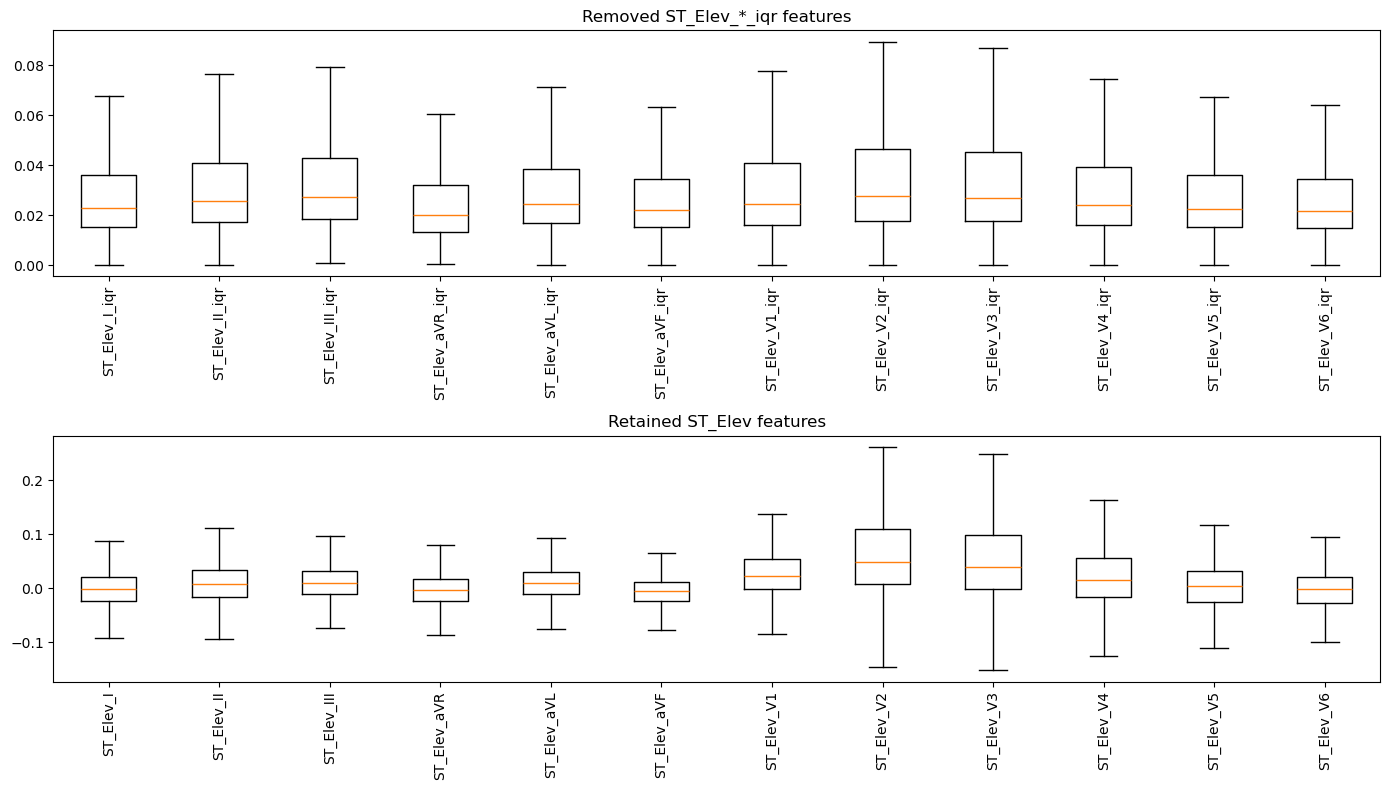

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].boxplot([df[feature].dropna().values for feature in removed_st_elev_iqr], labels=removed_st_elev_iqr, showfliers=False)
axes[0].set_title('Removed ST_Elev_*_iqr features')
axes[0].tick_params(axis='x', rotation=90)

axes[1].boxplot([df[feature].dropna().values for feature in retained_st_elev_mean], labels=retained_st_elev_mean, showfliers=False)
axes[1].set_title('Retained ST_Elev features')
axes[1].tick_params(axis='x', rotation=90)

plt.tight_layout()

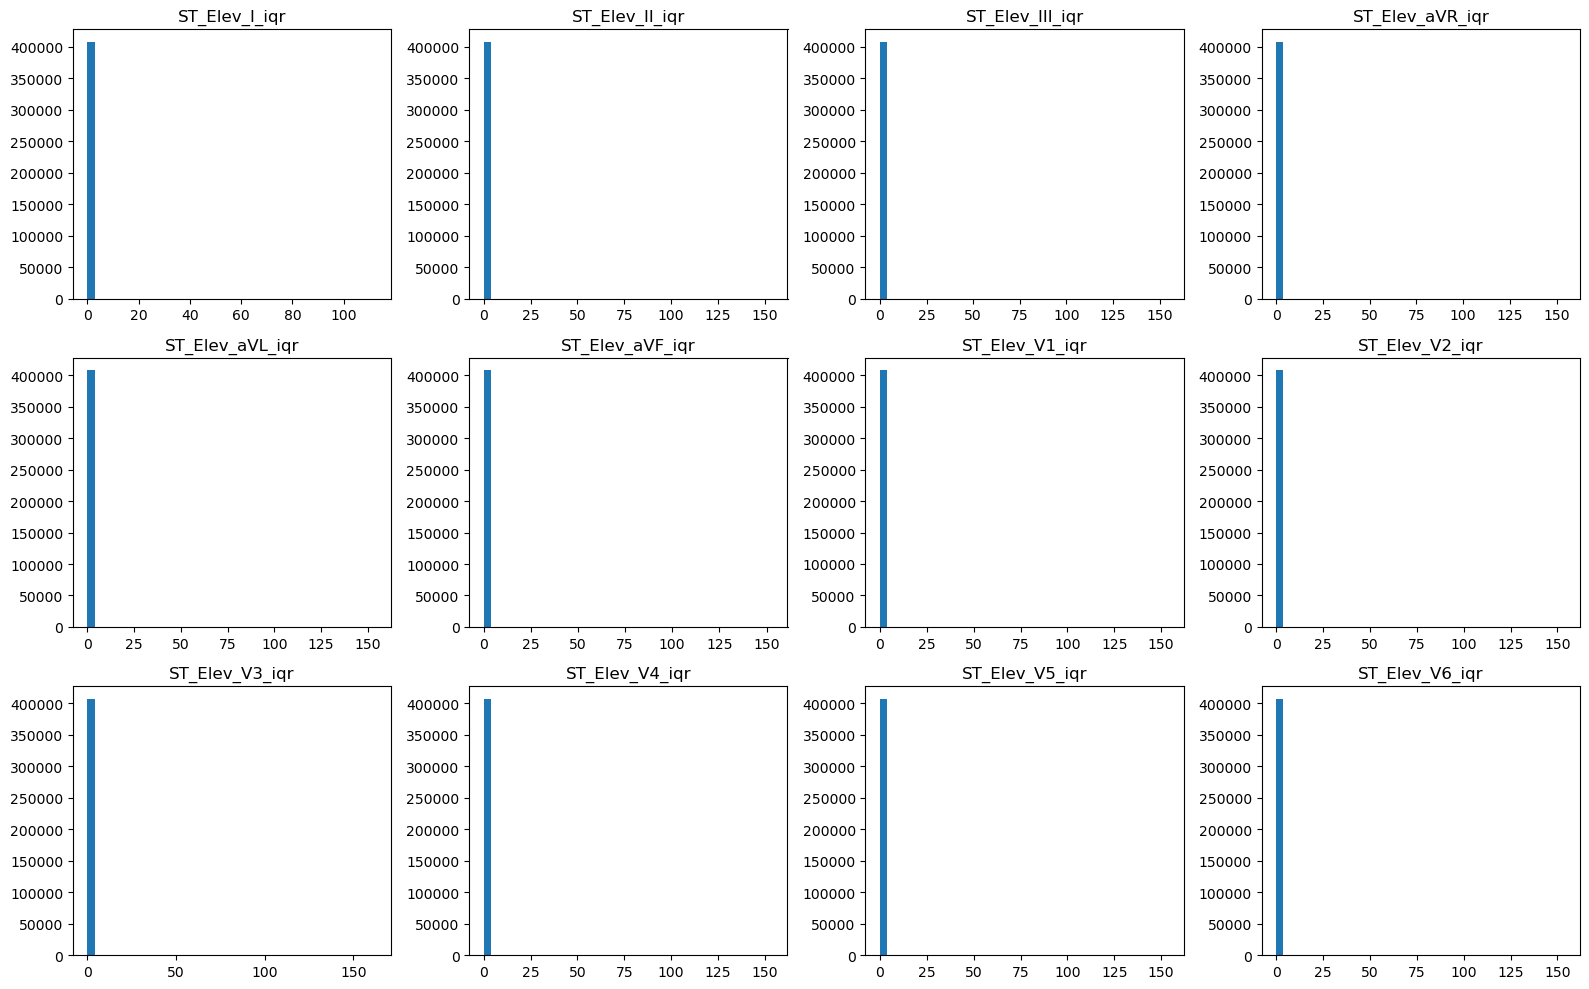

In [19]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, feature in zip(axes.ravel(), removed_st_elev_iqr):
    ax.hist(df[feature].dropna(), bins=40)
    ax.set_title(feature)
plt.tight_layout()

In [20]:
validation_candidates = []
search_terms = ['validation', 'plausibility', 'missingness', 'feature_quality', 'batch_effect', 'redundancy']

for path in PROJECT_ROOT.rglob('*'):
    if not path.is_file():
        continue
    lower_name = path.name.lower()
    if any(term in lower_name for term in search_terms):
        validation_candidates.append(path)

validation_candidates = [path for path in validation_candidates if path.suffix.lower() in {'.csv', '.txt', '.md'}]
pd.DataFrame({'validation_related_files_found': [str(path.relative_to(PROJECT_ROOT)) for path in validation_candidates]})

,validation_related_files_found
0,preprocessing_pipeline\outputs\datasets\valida...


In [21]:
structured_prior_validation_files = [
    path for path in validation_candidates
    if 'outputs/tables' in str(path).replace('\\', '/') or 'outputs/report' in str(path).replace('\\', '/')
]

if structured_prior_validation_files:
    prior_validation_note = 'Structured prior validation files are available to inspect directly in this repository.'
else:
    prior_validation_note = 'The previous validation supporting this removal is not available in this notebook as structured source files.'

display(Markdown(prior_validation_note))

The previous validation supporting this removal is not available in this notebook as structured source files.

### Interpretation

This section should separate **what the current dataset shows** from **what would require earlier validation artifacts**.

In [22]:
removed_missing_max = removed_st_stats['missing_pct'].max()
removed_variance_median = removed_st_stats['variance'].median()
removed_cv_median = removed_st_stats['coefficient_of_variation'].median()
retained_cv_median = retained_st_stats['coefficient_of_variation'].median()

observed_points = [
    f"Removed ST_Elev IQR features available in the processed dataset: `{len(removed_st_elev_iqr)}`.",
    f"Maximum missing percentage across removed ST_Elev IQR features: `{removed_missing_max:.6f}%`.",
    f"Median variance across removed ST_Elev IQR features: `{removed_variance_median:.6f}`.",
    f"Median coefficient of variation across removed ST_Elev IQR features: `{removed_cv_median:.6f}`.",
    f"Median coefficient of variation across retained ST_Elev mean features: `{retained_cv_median:.6f}`.",
]

if structured_prior_validation_files:
    conclusion_text = 'The notebook can combine current-dataset behavior with prior validation artifacts.'
else:
    conclusion_text = 'The notebook can describe these features in the current dataset, but it cannot independently reproduce the earlier reliability argument from structured validation files.'

display(Markdown(
    '**Observed evidence**  \n' + '\n'.join(f'- {point}  ' for point in observed_points) + '\n\n'
    + f'**Conclusion**  \n{conclusion_text}'
))

**Observed evidence**  
- Removed ST_Elev IQR features available in the processed dataset: `12`.  
- Maximum missing percentage across removed ST_Elev IQR features: `0.000000%`.  
- Median variance across removed ST_Elev IQR features: `0.151026`.  
- Median coefficient of variation across removed ST_Elev IQR features: `10.511041`.  
- Median coefficient of variation across retained ST_Elev mean features: `14.734662`.  

**Conclusion**  
The notebook can describe these features in the current dataset, but it cannot independently reproduce the earlier reliability argument from structured validation files.

# Summary Table

This table distinguishes direct notebook evidence from historical project decisions.

In [23]:
count_evidence_text = (
    f"Minimum absolute correlation across count features = {count_abs_corr_min:.6f}; "
    f"minimum exact match to {count_reference} = {count_exact_min:.6%}; "
    f"rows with one unique count value = {exactly_one_value_rows:,}."
)

st_evidence_text = (
    'Current-dataset descriptive statistics and plots were produced. '
    + ('Structured prior validation files are available here.' if structured_prior_validation_files else 'Prior validation proving unreliability is not available here as structured source files.')
)

summary_table = pd.DataFrame(
    [
        {
            'Feature Category': 'Count Features',
            'Reason for Removal': 'High redundancy',
            'Evidence Produced': count_evidence_text,
            'Confidence': 'High' if count_abs_corr_min >= 0.999 and count_exact_min >= 0.95 else 'Medium',
        },
        {
            'Feature Category': 'ST_Elev_*_iqr',
            'Reason for Removal': 'Historical reliability concern',
            'Evidence Produced': st_evidence_text,
            'Confidence': 'Medium' if not structured_prior_validation_files else 'High',
        },
    ]
)
summary_table

,Feature Category,Reason for Removal,Evidence Produced,Confidence
0,Count Features,High redundancy,Minimum absolute correlation across count feat...,High
1,ST_Elev_*_iqr,Historical reliability concern,Current-dataset descriptive statistics and plo...,Medium


# Final Conclusion

This final section should clearly separate what this notebook *observed directly* from what it inherits from earlier project decisions.

In [24]:
observed_evidence_lines = []
historical_decision_lines = []

if count_abs_corr_min >= 0.999 and count_exact_min >= 0.95:
    observed_evidence_lines.append('Count-feature removal is strongly supported by direct notebook evidence of redundancy.')
else:
    observed_evidence_lines.append('Count-feature redundancy is weaker than expected and should be reviewed further.')

if structured_prior_validation_files:
    observed_evidence_lines.append('Prior validation files are available in the repository, so the ST_Elev IQR decision can be inspected further here.')
else:
    historical_decision_lines.append('ST_Elev IQR removal still relies mainly on a historical project decision because the structured prior validation files are not present in this notebook environment.')

historical_decision_lines.append('The removal policy itself was fixed before this notebook; the purpose here is to test whether the current repository provides enough justification to understand it.')

final_markdown = '## Observed Evidence\n' + '\n'.join(f'- {line}' for line in observed_evidence_lines)
final_markdown += '\n\n## Historical Decision\n' + '\n'.join(f'- {line}' for line in historical_decision_lines)

display(Markdown(final_markdown))

## Observed Evidence
- Count-feature removal is strongly supported by direct notebook evidence of redundancy.

## Historical Decision
- ST_Elev IQR removal still relies mainly on a historical project decision because the structured prior validation files are not present in this notebook environment.
- The removal policy itself was fixed before this notebook; the purpose here is to test whether the current repository provides enough justification to understand it.